In [13]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)


import numpy as np
import tensorflow as tf
from tqdm import tqdm

from data_loaders.data_loader_patches import DataLoaderPatches
import project_images_loader as pil
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.util as util
import utils.visualization as vis
import matplotlib.pyplot as plt

from generator import MetamorphicGenerator
import discriminator as MetamorphicDiscriminator

import utils.patches_controller as patches_controller


# tf.config.set_visible_devices([], 'GPU')
# os.environ["CUDA_VISIBLE_DEVICES"]="-1"

from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

In [14]:
G_h4 = MetamorphicGenerator()

checkpoint_dir = f"{current_path}/models/training_checkpoints/"
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(G_h4 = G_h4)
# checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

In [15]:
def save_image(id, img_gen, img_path_name):
    _, affine = pil.load_preprocessed_image(3, id, absolute=True)
    pil.save_image(img_gen.astype(np.float32), affine, img_path_name)


def generate_image_step(img_org, G, patch_size, patch_step, batch_size=20):
    img_patches = patches_controller.extract_patches(img_org, patch_shape=patch_size, extraction_step=patch_step).astype(np.float32)
    gen_patches = np.zeros_like(img_patches)

    for i in tqdm(range(0, len(img_patches), batch_size)):
        patches_batch = np.expand_dims(img_patches[i:min(i+batch_size, len(img_patches))], axis=-1)
        gen_result = G(patches_batch, training=False)
        gen_patches[i:min(i+batch_size, len(img_patches))] = gen_result[-1][..., 0]

    gen_image = patches_controller.perform_voting(gen_patches, 
                                                  patch_shape=patch_size, 
                                                  expected_shape=img_org.shape, 
                                                  extraction_step=patch_step,
                                                  window_sep=patch_step)
    return gen_image


def generate_image(id, G, patch_size, patch_step, backward=False):
    img_hunt3, _ = pil.load_preprocessed_image(3, id, absolute=True)
    img_hunt4, _ = pil.load_preprocessed_image(4, id, absolute=True)

    if backward:
        img_gen = generate_image_step(img_hunt4, G, patch_size=patch_size, patch_step=patch_step)
    else:
        img_gen = generate_image_step(img_hunt3, G, patch_size=patch_size, patch_step=patch_step)
    return img_hunt3, img_hunt4, img_gen


-------- Checkpoint: 21
ID: 08202


100%|██████████| 8/8 [00:23<00:00,  2.91s/it]


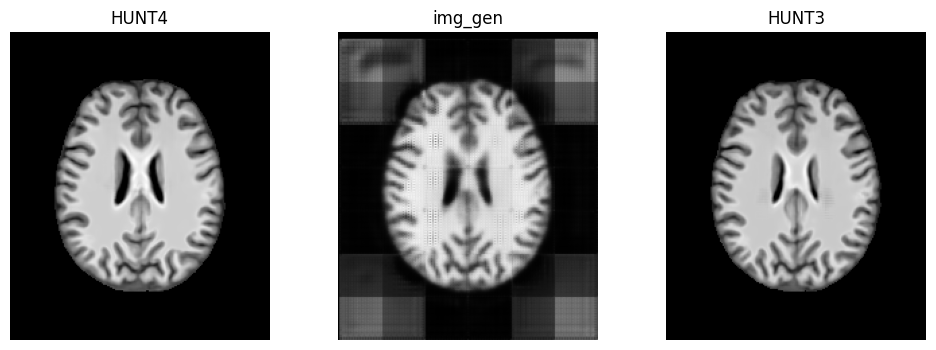

In [18]:
current_plane = 116

matching_ids = pil.get_matching_ids()
id_indexs = [366]
images_list = []
for checkpoint_index in [21]:
    print(f"-------- Checkpoint: {checkpoint_index}")
    checkpoint.restore(f"{checkpoint_dir}/ckpt-{checkpoint_index}")
    for id_index in id_indexs:
        id = matching_ids[id_index]
        print(f"ID: {id}")
        
        img_hunt3, img_hunt4, img_gen = generate_image(id, G_h4, patch_size=(64,64,64), patch_step=(32,32,32), backward=False)

        vis.shows_3_images(img_hunt3, img_hunt4, img_gen, current_plane=current_plane)
        # vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")
        # images_list.append([img_hunt3, img_hunt4, img_gen])

        # save image
        # save_image(id, img_gen, checkpoint_index)




In [22]:
for images in images_list:
    vis.shows_3_images(images[0], images[1], images[2], current_plane=118)

In [23]:
for images in images_list:
    vis.shows_3_images(images[0], images[1], images[2], current_plane=118)

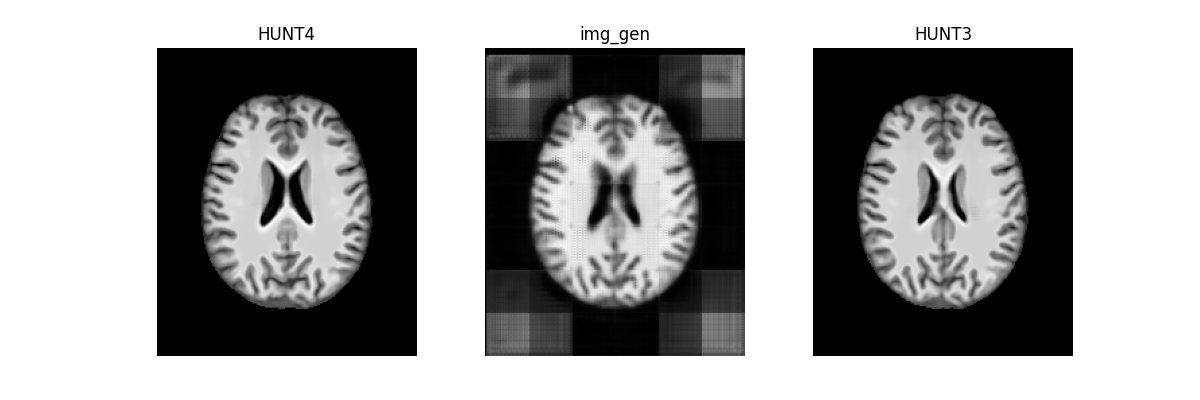

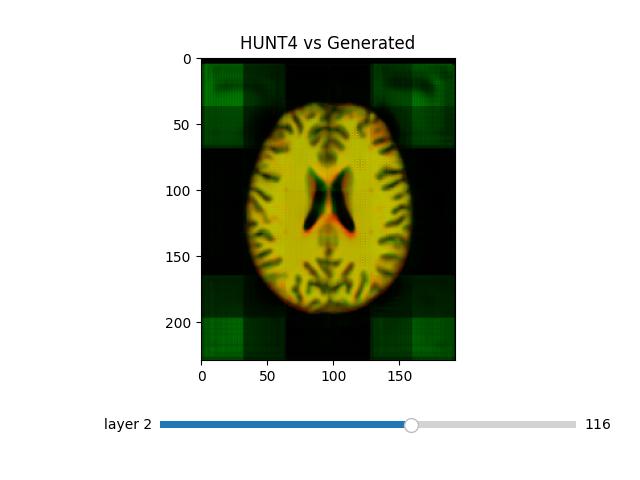

In [27]:
# %matplotlib widget
vis.shows_3_images(img_hunt3, img_hunt4, img_gen, current_plane=116)
vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")
